# Model comparison and chosen models

**Deliverables 4 and 5:** the model comparison table on the validation set, and for each chosen model the test-set
median and 95th-percentile error, a predicted-vs-SPICE plot and the saved model file.

| Section | Content |
|---|---|
| 1. Model comparison (validation set) | every model type × case: R², median and 95th-percentile error (plus mean) |
| 2. Chosen models | the model chosen for each case, why, and its saved file |
| 3. Test-set results | the chosen models on the test set, computed here from the saved files |
| 4. Predicted vs SPICE | one parity plot per case (test set) |

**How it works**
- The comparison table is read from the result files the training notebooks write (`validation_comparison_*.csv`
  in this folder).
- The chosen models are **loaded from `ML_Models/Saved_Models/`** with `ML_Models/Scripts/leakage_model.py` and evaluated
  here. The test set is used **only in this notebook**.
- Cases without results yet (e.g. NMOS, from the other training notebook) are listed as missing.

**Files written:** `test_results.csv` (this folder) and `parity_<case>.png` (`ML_Models/Plots/`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "ML_Models" / "Scripts"))
from leakage_model import LeakageModel, OUTPUT_COLS, error_table, split_indices

DATA_DIR    = ROOT / "Data_Generation" / "Datasets"
RESULTS_DIR = ROOT / "ML_Models" / "Results"
MODEL_DIR   = ROOT / "ML_Models" / "Saved_Models"
PLOT_DIR    = ROOT / "ML_Models" / "Plots"
CASES = ["NMOS_ON", "NMOS_OFF", "PMOS_ON", "PMOS_OFF"]
MODEL_ORDER = ["Random forest", "XGBoost", "Polynomial (Ridge)", "MLP", "MLP + Kirchhoff loss"]
METRICS = ["R2 (log|I|)", "median err %", "95th pct err %", "mean err %"]

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
BLUE, LIGHT_BLUE = "#2a78d6", "#9ec5f4"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9, "legend.frameon": False,
})

## 1. Model comparison table — validation set

- **R²** on log10|I|
- **% error** = |I_pred / I_SPICE − 1| × 100, summarized by its **median**, **95th percentile** and **mean**
- Each value is the **average over the four currents** (id, ig, is, ib); the per-current values follow below.
- Rows are the four model types, plus the MLP trained with the Kirchhoff (physics-informed) loss as a variant.

In [2]:
files = sorted(RESULTS_DIR.glob("validation_comparison_*.csv"))
comparison = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print("result files:", ", ".join(f.name for f in files))
missing = [c for c in CASES if c not in set(comparison["case"])]
print("cases without results yet:", ", ".join(missing) if missing else "none")

avg = comparison[comparison["current"] == "average"]
table = avg.pivot_table(index="model", columns="case", values=METRICS)
table = table.swaplevel(axis=1)                                       # columns: (case, metric)
table = table.reindex(columns=[(c, m) for c in CASES for m in METRICS if (c, m) in table.columns])
table = table.reindex([m for m in MODEL_ORDER if m in table.index])
table

result files: validation_comparison_PMOS.csv
cases without results yet: NMOS_ON, NMOS_OFF


case                     PMOS_ON                                         \
                     R2 (log|I|) median err % 95th pct err % mean err %   
model                                                                     
Random forest              0.988         14.2           54.4       20.3   
XGBoost                    0.999         2.86           12.6       4.37   
Polynomial (Ridge)         0.997         4.46           22.1       7.02   
MLP                            1        0.345           1.62      0.559   
MLP + Kirchhoff loss           1        0.426           2.15      0.761   

case                    PMOS_OFF                                         
                     R2 (log|I|) median err % 95th pct err % mean err %  
model                                                                    
Random forest              0.923         9.75           49.8       29.2  
XGBoost                    0.985         3.33           19.4       13.4  
Polynomial (Ridge)         0.868         14.6           77.3         70  
MLP                         0.99         0.33           2.02       1.83  
MLP + Kirchhoff loss       0.991        0.346           2.25        1.5

In [3]:
# per current: median and 95th-percentile error on the validation set
per_current = comparison[comparison["current"] != "average"].pivot_table(
    index=["case", "model"], columns="current", values=["median err %", "95th pct err %"])
per_current = per_current.swaplevel(axis=1)
per_current = per_current.reindex(columns=[(c, m) for c in OUTPUT_COLS for m in ["median err %", "95th pct err %"]])
per_current.reindex([(c, m) for c in CASES for m in MODEL_ORDER if (c, m) in per_current.index])

current                                 id                          ig  \
                              median err % 95th pct err % median err %   
case     model                                                           
PMOS_ON  Random forest                11.1           46.8         13.3   
         XGBoost                      1.86           12.5         2.29   
         Polynomial (Ridge)           4.01           13.3         5.25   
         MLP                         0.339           1.33        0.267   
         MLP + Kirchhoff loss        0.359           1.63        0.426   
PMOS_OFF Random forest                11.9           55.6         11.4   
         XGBoost                       5.1           33.4         3.16   
         Polynomial (Ridge)           25.6            125         1.99   
         MLP                         0.437           2.59        0.333   
         MLP + Kirchhoff loss         0.47           2.75        0.304   

current                                                is                 \
                              95th pct err % median err % 95th pct err %   
case     model                                                             
PMOS_ON  Random forest                  53.4         11.1           46.8   
         XGBoost                        8.62         1.88           12.8   
         Polynomial (Ridge)             45.6         4.03           13.1   
         MLP                            1.85        0.338           1.53   
         MLP + Kirchhoff loss           2.76        0.359           1.61   
PMOS_OFF Random forest                  54.6           12           58.7   
         XGBoost                        10.3         4.97           31.7   
         Polynomial (Ridge)             8.37         25.9            152   
         MLP                            1.63        0.429           2.66   
         MLP + Kirchhoff loss           1.77        0.468              3   

current                                 ib                 
                              median err % 95th pct err %  
case     model                                             
PMOS_ON  Random forest                21.2           70.7  
         XGBoost                       5.4           16.5  
         Polynomial (Ridge)           4.55           16.4  
         MLP                         0.436           1.77  
         MLP + Kirchhoff loss        0.559           2.62  
PMOS_OFF Random forest                3.69           30.5  
         XGBoost                     0.107           2.35  
         Polynomial (Ridge)           4.85           24.1  
         MLP                         0.119            1.2  
         MLP + Kirchhoff loss        0.141           1.49

## 2. Chosen models

**Rule:** for each case, the model with the lowest validation **mean** error (average over the four currents), because
the project targets mean accuracy. Each saved file is self-contained: network weights, hidden layers, feature list and
both scalers.

In [4]:
models, rows = {}, []
for case in CASES:
    path = MODEL_DIR / f"{case}.pt"
    if not path.exists():
        rows.append({"case": case, "model": "— not saved yet —"})
        continue
    m = LeakageModel(path)
    models[case] = m
    v = m.info["validation"]
    rows.append({"case": case, "model": m.info["model"], "hidden layers": "-".join(map(str, m.info["hidden"])),
                 "Kirchhoff λ": m.info.get("kirchhoff_lambda", 0.0),
                 "val median err %": v["median err %"], "val 95th pct err %": v["95th pct err %"], "val mean err %": v["mean err %"],
                 "file": str(path.relative_to(ROOT)), "size kB": path.stat().st_size / 1024})
pd.DataFrame(rows).set_index("case")

,model,hidden layers,Kirchhoff λ,val median err %,val 95th pct err %,val mean err %,file,size kB
case,,,,,,,,
NMOS_ON,— not saved yet —,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NMOS_OFF,— not saved yet —,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PMOS_ON,MLP,128-64-32-16,0,0.345,1.62,0.559,ML_Models/Saved_Models/PMOS_ON.pt,60.4
PMOS_OFF,MLP + Kirchhoff loss,128-64-32-32,30,0.346,2.25,1.5,ML_Models/Saved_Models/PMOS_OFF.pt,63.3


## 3. Test-set results

The test set is the same 10 % (2,000 samples) as in training: the 80 / 10 / 10 split is rebuilt here from the dataset
with the same seed. It was not used for training or for choosing any setting.

First, a **reproduction check**: the validation error recomputed here from the saved file must equal the value stored
by the training notebook, which proves that the file holds exactly the trained model.

In [5]:
test_tables, check, PRED = {}, [], {}
for case, m in models.items():
    df = pd.read_csv(DATA_DIR / m.info["dataset"])
    Y_log = np.log10(df[OUTPUT_COLS].abs()).values
    idx_train, idx_val, idx_test = split_indices(len(df), m.info["seed"])
    val = error_table(Y_log[idx_val], m.predict_log(df.iloc[idx_val])).loc["average"]
    check.append({"case": case, "val mean err % (training notebook)": m.info["validation"]["mean err %"],
                  "val mean err % (recomputed from file)": val["mean err %"],
                  "match": bool(np.isclose(val["mean err %"], m.info["validation"]["mean err %"], rtol=1e-4))})
    pred_test = m.predict_log(df.iloc[idx_test])
    test_tables[case] = error_table(Y_log[idx_test], pred_test)
    PRED[case] = (Y_log[idx_test], pred_test)
pd.DataFrame(check).set_index("case")

,val mean err % (training notebook),val mean err % (recomputed from file),match
case,,,
PMOS_ON,0.559,0.559,True
PMOS_OFF,1.5,1.5,True


In [6]:
test_results = pd.concat(test_tables, names=["case", "current"])
test_results.to_csv(RESULTS_DIR / "test_results.csv")

# summary: chosen model per case, validation vs test (average over the four currents)
summary = pd.DataFrame({case: {"model": models[case].info["model"],
                               "val median err %": models[case].info["validation"]["median err %"],
                               "test median err %": t.loc["average", "median err %"],
                               "val 95th pct err %": models[case].info["validation"]["95th pct err %"],
                               "test 95th pct err %": t.loc["average", "95th pct err %"],
                               "test mean err %": t.loc["average", "mean err %"],
                               "test R2 (log|I|)": t.loc["average", "R2 (log|I|)"]}
                        for case, t in test_tables.items()}).T
display(summary)

# test set, per current
test_results

,model,val median err %,test median err %,val 95th pct err %,test 95th pct err %,test mean err %,test R2 (log|I|)
PMOS_ON,MLP,0.345,0.348,1.62,1.56,0.651,1
PMOS_OFF,MLP + Kirchhoff loss,0.346,0.357,2.25,2.13,1.3,0.992


R2 (log|I|)  mean err %  median err %  95th pct err %
case     current                                                       
PMOS_ON  id             0.999       0.916         0.342            1.34
         ig                 1        0.54         0.276            1.73
         is                 1       0.507         0.337            1.39
         ib                 1       0.641         0.435            1.79
         average            1       0.651         0.348            1.56
PMOS_OFF id             0.997        2.17         0.495             2.9
         ig             0.999       0.781         0.312            1.68
         is             0.999        1.18         0.478            2.67
         ib             0.972        1.07         0.145            1.27
         average        0.992         1.3         0.357            2.13

## 4. Predicted vs SPICE — test set

Each point is one test sample; the dashed line is a perfect prediction. Axes are logarithmic because the currents
span many decades. Current magnitudes are shown; the signs are handled separately in Part B.

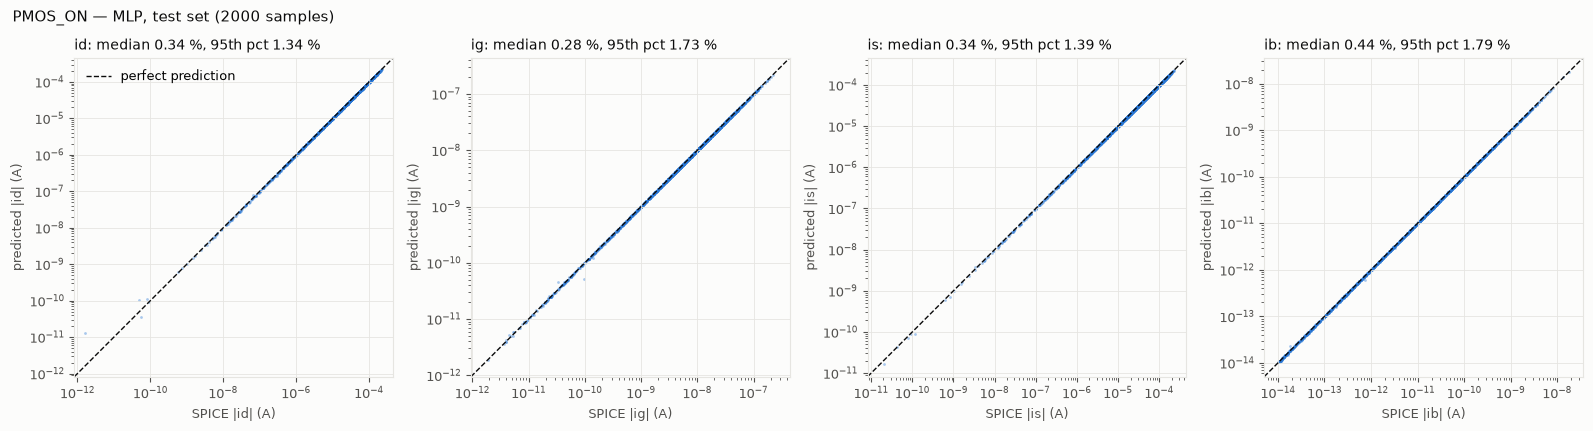

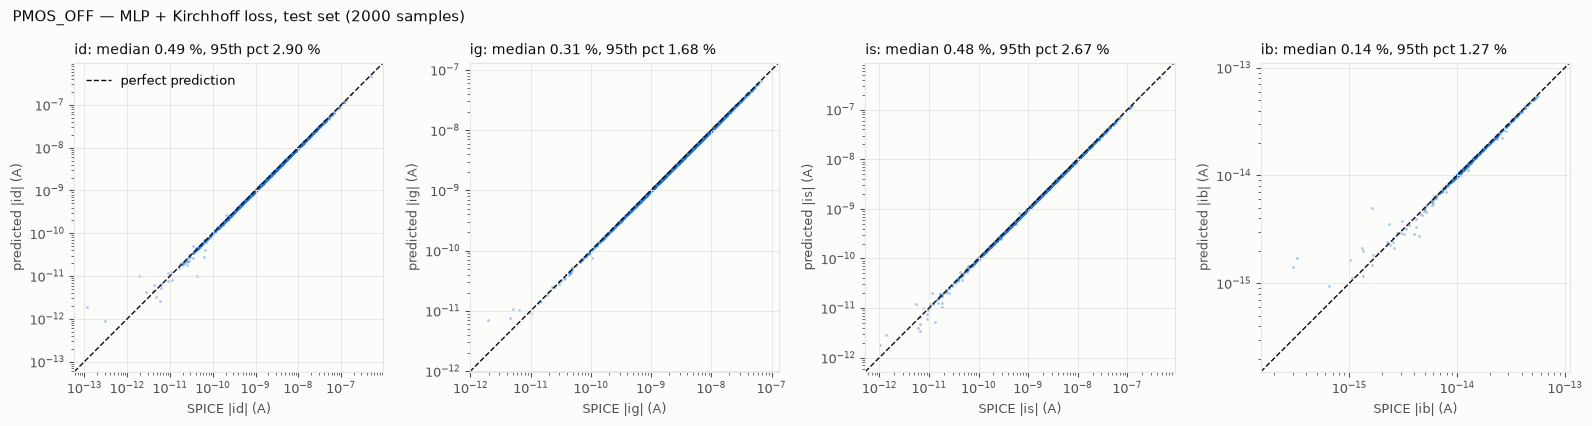

In [7]:
for case, (Y_true, Y_pred) in PRED.items():
    t = test_tables[case]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
    for k, (ax, c) in enumerate(zip(axes, OUTPUT_COLS)):
        x, y = 10 ** Y_true[:, k], 10 ** Y_pred[:, k]
        lo, hi = min(x.min(), y.min()) / 2, max(x.max(), y.max()) * 2
        ax.plot([lo, hi], [lo, hi], color=INK, lw=1, ls="--", label="perfect prediction")
        ax.scatter(x, y, s=4, alpha=0.4, color=BLUE, linewidths=0, rasterized=True)
        ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi), aspect="equal",
               xlabel=f"SPICE |{c}| (A)", ylabel=f"predicted |{c}| (A)")
        ax.set_title(f"{c}: median {t.loc[c, 'median err %']:.2f} %, 95th pct {t.loc[c, '95th pct err %']:.2f} %", loc="left")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{case} — {models[case].info['model']}, test set ({len(Y_true)} samples)",
                 color=INK, fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"parity_{case}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Summary

In [8]:
for case in CASES:
    if case not in test_tables:
        print(f"{case:9s} not available yet")
        continue
    a = test_tables[case].loc["average"]
    print(f"{case:9s} {models[case].info['model']:22s} test: median {a['median err %']:.2f} %   "
          f"95th pct {a['95th pct err %']:.2f} %   mean {a['mean err %']:.2f} %")

NMOS_ON   not available yet
NMOS_OFF  not available yet
PMOS_ON   MLP                    test: median 0.35 %   95th pct 1.56 %   mean 0.65 %
PMOS_OFF  MLP + Kirchhoff loss   test: median 0.36 %   95th pct 2.13 %   mean 1.30 %
